# Bee Quest: Predicting a Player's Value From Their First Week

**Bee Quest** is a free-to-play mobile game of the "farm with expeditions" kind: the player grows a farm, raises bees, and sends them on adventure expeditions. The game earns money from in-game purchases and ads. The data is an event log of its players over their first 120 days.

The task: build a system that predicts how much money each player brings in over 120 days after registration (their **LTV**, lifetime value), early enough to judge a marketing campaign.

This notebook:
1. looks at where the game's revenue comes from,
2. builds features from each player's first 7 days,
3. predicts 120-day revenue in two steps (will the player spend at all? if so, how much?),
4. checks the forecast against a simple rule of thumb.

**Data:** [task.csv.gz](task.csv.gz), synthetic, generated by [make_data.py](make_data.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})
DAY = 86_400

In [2]:
task = pd.read_csv("task.csv.gz")
task.head(8)

,id,cc,eventId,eventSar,eventValue
0,1,US,1,0,0.0
1,1,US,4,1413,1.0
2,1,US,1,9900,0.0
3,1,US,3,9960,2.0
4,1,US,1,44364,0.0
5,1,US,3,44424,3.0
6,1,US,1,136864,0.0
7,1,US,1,154791,0.0


Each row is one event of one player:

- `id`: the player; `cc`: registration country
- `eventId`: 1 login, 2 purchase, 3 new farm level, 4 tutorial finished, 5 ad watched
- `eventSar`: seconds since the player first launched the game
- `eventValue`: money paid for a purchase or earned from an ad; the new level for a level-up; 1 for the tutorial; 0 for a login

For readability, the columns get plain names below.

In [3]:
names = {1: "login", 2: "purchase", 3: "level_up", 4: "tutorial_done", 5: "ad_view"}
events = task.rename(columns={"id": "player_id", "cc": "country", "eventSar": "seconds", "eventValue": "value"})
events["event"] = events.pop("eventId").map(names)
print(f"{events.player_id.nunique():,} players, {len(events):,} events")

20,000 players, 742,749 events


## 1. Where the revenue comes from

In [4]:
money = events[events.event.isin(["purchase", "ad_view"])]
players = events.groupby("player_id").agg(country=("country", "first"), last_seen=("seconds", "max"))
players["ltv"] = money.groupby("player_id").value.sum().reindex(players.index, fill_value=0)

print(f"total revenue: ${players.ltv.sum():,.0f}")
print(f"from purchases: {money[money.event == 'purchase'].value.sum() / players.ltv.sum():.0%}, from ads: {money[money.event == 'ad_view'].value.sum() / players.ltv.sum():.0%}")
print(f"players who bought something: {events[events.event == 'purchase'].player_id.nunique() / len(players):.1%}")

total revenue: $14,907
from purchases: 56%, from ads: 44%
players who bought something: 5.2%


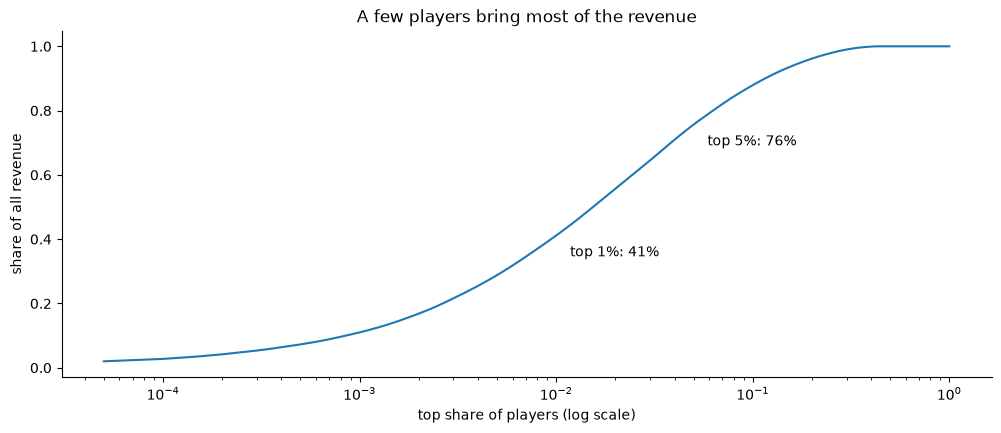

In [5]:
ranked = players.ltv.sort_values(ascending=False).cumsum() / players.ltv.sum()
share_of_players = np.arange(1, len(ranked) + 1) / len(ranked)
fig, ax = plt.subplots()
ax.plot(share_of_players, ranked.values)
ax.set_xscale("log")
ax.set_xlabel("top share of players (log scale)")
ax.set_ylabel("share of all revenue")
ax.set_title("A few players bring most of the revenue")
for top in [0.01, 0.05]:
    value = ranked.iloc[int(top * len(ranked)) - 1]
    ax.annotate(f"top {top:.0%}: {value:.0%}", (top, value), textcoords="offset points", xytext=(10, -15))
plt.show()

In [6]:
by_country = players.groupby("country").agg(players=("ltv", "size"), revenue=("ltv", "sum"))
by_country["share of players"] = by_country.players / by_country.players.sum()
by_country["share of revenue"] = by_country.revenue / by_country.revenue.sum()
by_country["revenue per player"] = by_country.revenue / by_country.players
by_country.sort_values("revenue", ascending=False).round(3)

,players,revenue,share of players,share of revenue,revenue per player
country,,,,,
US,7152,6560.250,0.358,0.440,0.917
GB,1142,1506.262,0.057,0.101,1.319
DE,1034,1083.490,0.052,0.073,1.048
BR,1981,959.176,0.099,0.064,0.484
IN,2224,902.007,0.111,0.061,0.406
FR,986,811.547,0.049,0.054,0.823
AU,778,737.181,0.039,0.049,0.948
PH,1560,718.941,0.078,0.048,0.461
CA,1016,626.364,0.051,0.042,0.617


## 2. How long players stay

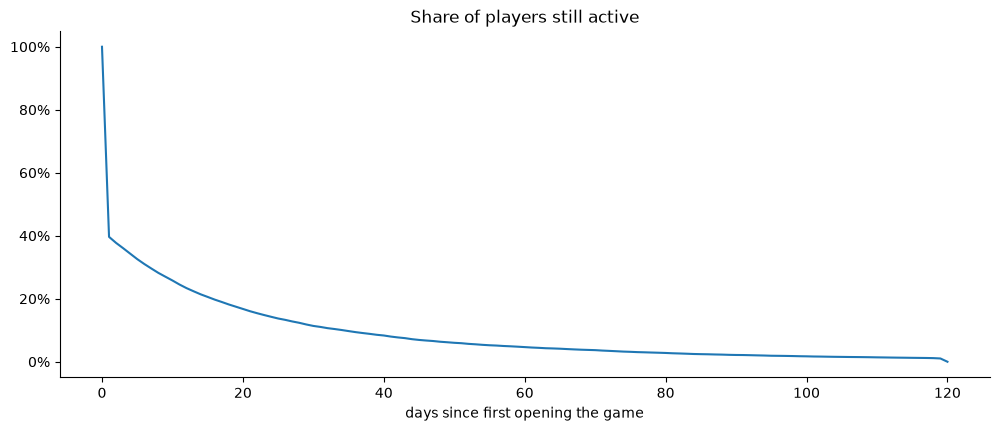

median time between first and last event: 24 minutes
still active after day 1: 39.6%
still active after day 7: 29.6%
still active after day 30: 11.4%


In [7]:
days = np.arange(0, 121)
still_playing = [(players.last_seen >= d * DAY).mean() for d in days]
fig, ax = plt.subplots()
ax.plot(days, still_playing)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("days since first opening the game")
ax.set_title("Share of players still active")
plt.show()
print(f"median time between first and last event: {players.last_seen.median() / 60:.0f} minutes")
for d in [1, 7, 30]:
    print(f"still active after day {d}: {(players.last_seen >= d * DAY).mean():.1%}")

Most players leave within the first hour. The ones who stay a week are worth looking at closely, and that is the moment the forecast is made.

## 3. Features from the first week

Everything the model sees comes from the first 7 days; the answer it learns is the revenue over 120 days.

In [8]:
week = events[events.seconds <= 7 * DAY]
logins = week[week.event == "login"]
features = pd.DataFrame(index=players.index)
features["logins"] = logins.groupby("player_id").size()
features["active_days"] = logins.assign(day=logins.seconds // DAY).groupby("player_id").day.nunique()
for d in [1, 3, 6]:
    features[f"back_on_day_{d}"] = logins[(logins.seconds >= d * DAY) & (logins.seconds < (d + 1) * DAY)].groupby("player_id").size().gt(0)
features["finished_tutorial"] = week[week.event == "tutorial_done"].groupby("player_id").size().gt(0)
features["level"] = week[week.event == "level_up"].groupby("player_id").value.max()
features["ads_watched"] = week[week.event == "ad_view"].groupby("player_id").size()
features["purchases"] = week[week.event == "purchase"].groupby("player_id").size()
features["revenue_week_1"] = week[week.event.isin(["purchase", "ad_view"])].groupby("player_id").value.sum()
features["minutes_played_span"] = week.groupby("player_id").seconds.max() / 60
features = features.fillna(0).astype(float)
features["level"] = features["level"].clip(lower=1)
features["country"] = players.country.astype("category")
features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
logins,20000.0,4.92,6.88,1.0,1.00,1.00,7.00,108.00
active_days,20000.0,2.54,2.13,1.0,1.00,1.00,4.00,7.00
back_on_day_1,20000.0,0.28,0.45,0.0,0.00,0.00,1.00,1.00
back_on_day_3,20000.0,0.26,0.44,0.0,0.00,0.00,1.00,1.00
back_on_day_6,20000.0,0.23,0.42,0.0,0.00,0.00,0.00,1.00
finished_tutorial,20000.0,0.69,0.46,0.0,0.00,1.00,1.00,1.00
level,20000.0,2.47,2.39,1.0,1.00,1.00,3.00,28.00
ads_watched,20000.0,1.77,3.25,0.0,0.00,0.00,3.00,49.00
purchases,20000.0,0.03,0.21,0.0,0.00,0.00,0.00,4.00
revenue_week_1,20000.0,0.14,0.72,0.0,0.00,0.00,0.09,37.69


## 4. Two-step forecast

Over half of the players bring in nothing, and a few bring in a lot. One model struggles with both, so the forecast has two steps:

1. a classifier estimates the chance that the player brings in more than \$1 by day 120,
2. a regressor, trained only on those players, estimates how much.

The forecast is chance × amount, plus (1 − chance) × the average revenue of a player who stays under \$1, which comes mostly from ads. Both are LightGBM models. The players are split 60% / 20% / 20% into training, validation, and test sets; all numbers below are on the test players, whom the models never saw.

In [9]:
y = players.ltv
spender = (y > 1).astype(int)
ids_train, ids_rest = train_test_split(players.index, test_size=0.4, random_state=42, stratify=spender)
ids_valid, ids_test = train_test_split(ids_rest, test_size=0.5, random_state=42, stratify=spender[ids_rest])

params = dict(learning_rate=0.05, num_leaves=31, min_child_samples=40, verbose=-1, seed=42)
stop = [lgb.early_stopping(50, verbose=False)]

classifier = lgb.train({**params, "objective": "binary"},
                       lgb.Dataset(features.loc[ids_train], spender[ids_train]), 1000,
                       valid_sets=[lgb.Dataset(features.loc[ids_valid], spender[ids_valid])], callbacks=stop)

pay_train = [i for i in ids_train if y[i] > 1]
pay_valid = [i for i in ids_valid if y[i] > 1]
regressor = lgb.train({**params, "objective": "regression"},
                      lgb.Dataset(features.loc[pay_train], np.log1p(y[pay_train])), 1000,
                      valid_sets=[lgb.Dataset(features.loc[pay_valid], np.log1p(y[pay_valid]))], callbacks=stop)

chance = pd.Series(classifier.predict(features.loc[ids_test]), index=ids_test)
# a model fitted on log(revenue) predicts a typical amount, which is lower than the average;
# the smearing factor from the validation players corrects for that
residuals = np.log1p(y[pay_valid]) - regressor.predict(features.loc[pay_valid])
smearing = np.mean(np.exp(residuals))
amount = pd.Series(np.expm1(regressor.predict(features.loc[ids_test])) * smearing, index=ids_test)
small = y[ids_train][y[ids_train] <= 1].mean()      # average revenue of a player who stays under $1, mostly ads
forecast = chance * amount + (1 - chance) * small
print(f"smearing factor: {smearing:.2f}")
print(f"classifier AUC on test players: {roc_auc_score(spender[ids_test], chance):.3f}")

smearing factor: 1.21
classifier AUC on test players: 0.955


### A rule of thumb to beat

Without a model, a common estimate is: 120-day revenue = first-week revenue × (total 120-day revenue ÷ total first-week revenue), with the multiplier taken from the training players.

In [10]:
multiplier = y[ids_train].sum() / features.loc[ids_train, "revenue_week_1"].sum()
rule = features.loc[ids_test, "revenue_week_1"] * multiplier
actual = y[ids_test]
print(f"multiplier: {multiplier:.1f}")

def top_decile_share(pred):
    top = pred.sort_values(ascending=False).index[: len(pred) // 10]
    return actual[top].sum() / actual.sum()

comparison = pd.DataFrame({
    "average error per player, USD": [(rule - actual).abs().mean(), (forecast - actual).abs().mean()],
    "total forecast vs. actual": [rule.sum() / actual.sum() - 1, forecast.sum() / actual.sum() - 1],
    "revenue caught by the top 10% picked": [top_decile_share(rule), top_decile_share(forecast)],
}, index=["rule of thumb", "two-step model"])
comparison.round(3)

multiplier: 5.5


,"average error per player, USD",total forecast vs. actual,revenue caught by the top 10% picked
rule of thumb,0.670,-0.100,0.710
two-step model,0.619,-0.157,0.736


The last column matters most for marketing: if the team could only keep the 10% of new players a forecast ranks highest, how much of the cohort's eventual revenue would those players bring?

### What the model relies on

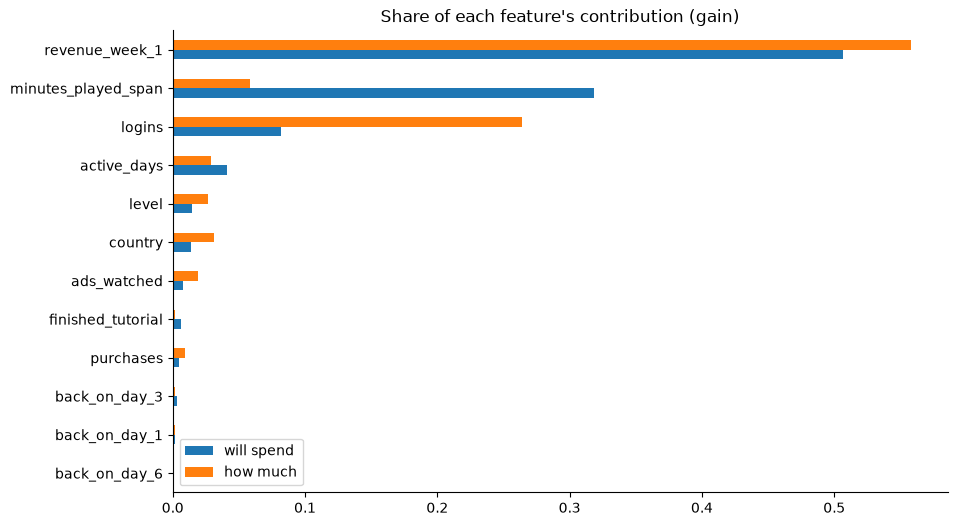

In [11]:
importance = pd.DataFrame({
    "will spend": pd.Series(classifier.feature_importance("gain"), index=features.columns),
    "how much": pd.Series(regressor.feature_importance("gain"), index=features.columns),
})
(importance / importance.sum()).sort_values("will spend").plot.barh(figsize=(10, 6), title="Share of each feature's contribution (gain)")
plt.show()

## Results

- Revenue is concentrated: the top 1% of players bring about 41% of it and the top 5% about 76%. Purchases bring 56% and ads 44%; only about 5% of players ever buy something. US players are 36% of the audience and 44% of the revenue.
- Most players leave quickly (median 24 minutes between the first and last event); about 30% are still around after a week and 11% after a month.
- First-week revenue, how long the player kept coming back, and the number of logins matter most. Single-day return flags add almost nothing once those are known.
- The classifier separates future spenders from the rest well (AUC 0.96). Per player, the two-step model is more accurate than the rule of thumb (an average error of \$0.62 against \$0.67), and the 10% of players it ranks highest bring 74% of the revenue, against 71%.
- For the cohort's total, the rule of thumb comes out closer here: 10% below the actual, against 16% for the model. The model is the better tool for picking which players and campaigns are valuable; the simple rule is a good check on the total.

## Using it

A week after a marketing campaign starts, the team computes these features for the campaign's new players and sums their forecasts. Comparing that with the campaign's cost shows whether it will pay off, long before the 120 days are up. The model should be retrained as the game and its audience change.

## Tools

Python, pandas, NumPy, LightGBM, scikit-learn, matplotlib